In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans

print("Libraries imported successfully!")

Libraries imported successfully!


In [5]:
from google.colab import files

uploaded = files.upload()

Saving mall_customers_200 (1).csv to mall_customers_200 (1) (1).csv


In [9]:
from google.colab import files
import pandas as pd

uploaded = files.upload()

filename = list(uploaded.keys())[0]

df = pd.read_csv(filename)

print("Dataset loaded successfully!")
display(df.head(10))

print("Dataset Shape:", df.shape)

Saving mall_customers_200.csv to mall_customers_200.csv
Dataset loaded successfully!


,CustomerID,Annual_Income_k,Spending_Score
0,CUST001,48,51
1,CUST002,29,87
2,CUST003,74,85
3,CUST004,86,18
4,CUST005,24,22
5,CUST006,62,45
6,CUST007,81,20
7,CUST008,51,45
8,CUST009,21,13
9,CUST010,61,38


Dataset Shape: (200, 3)


In [10]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Missing Values:
CustomerID         0
Annual_Income_k    0
Spending_Score     0
dtype: int64

Duplicate Rows:
0


In [11]:
X = df[['Annual_Income_k', 'Spending_Score']]

print(X.head())

   Annual_Income_k  Spending_Score
0               48              51
1               29              87
2               74              85
3               86              18
4               24              22


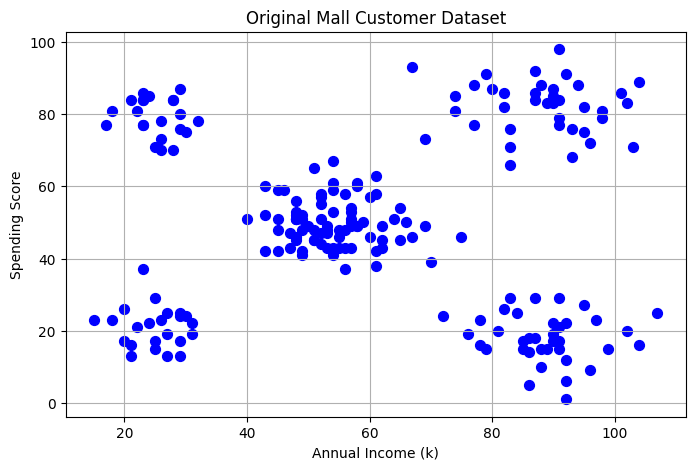

In [12]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df['Annual_Income_k'],
    df['Spending_Score'],
    color='blue',
    s=50
)

plt.title('Original Mall Customer Dataset')
plt.xlabel('Annual Income (k)')
plt.ylabel('Spending Score')

plt.grid(True)
plt.show()

In [13]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df['Cluster'] = kmeans.fit_predict(X)

print("Customer Cluster Assignments:")

display(df[['CustomerID',
            'Annual_Income_k',
            'Spending_Score',
            'Cluster']])

Customer Cluster Assignments:


,CustomerID,Annual_Income_k,Spending_Score,Cluster
0,CUST001,48,51,2
1,CUST002,29,87,2
2,CUST003,74,85,1
3,CUST004,86,18,0
4,CUST005,24,22,2
...,...,...,...,...
195,CUST196,24,85,2
196,CUST197,52,57,2
197,CUST198,87,18,0
198,CUST199,29,80,2


In [14]:
centroids = kmeans.cluster_centers_

print("Centroid Coordinates:")

for i, centroid in enumerate(centroids):
    print(
        f"Cluster {i}: "
        f"Income = {centroid[0]:.2f}, "
        f"Spending Score = {centroid[1]:.2f}"
    )

Centroid Coordinates:
Cluster 0: Income = 87.87, Spending Score = 19.33
Cluster 1: Income = 88.05, Spending Score = 82.18
Cluster 2: Income = 43.21, Spending Score = 49.76


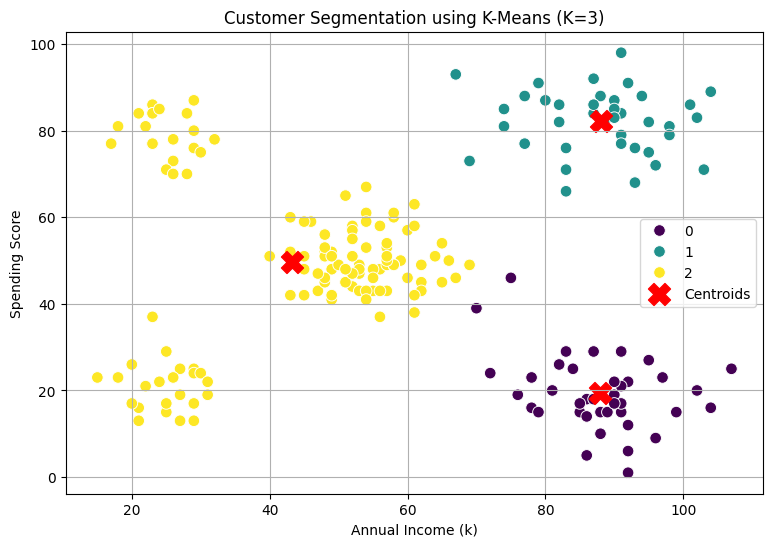

In [15]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x='Annual_Income_k',
    y='Spending_Score',
    hue='Cluster',
    palette='viridis',
    s=70
)

plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    color='red',
    marker='X',
    s=250,
    label='Centroids'
)

plt.title('Customer Segmentation using K-Means (K=3)')
plt.xlabel('Annual Income (k)')
plt.ylabel('Spending Score')

plt.legend()
plt.grid(True)
plt.show()

In [16]:
wcss = []

for k in range(1, 7):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X)

    wcss.append(model.inertia_)

    print(f"K = {k}, WCSS = {model.inertia_:.2f}")

K = 1, WCSS = 250999.26
K = 2, WCSS = 163520.73
K = 3, WCSS = 80123.30
K = 4, WCSS = 47249.82
K = 5, WCSS = 17800.29
K = 6, WCSS = 15323.49


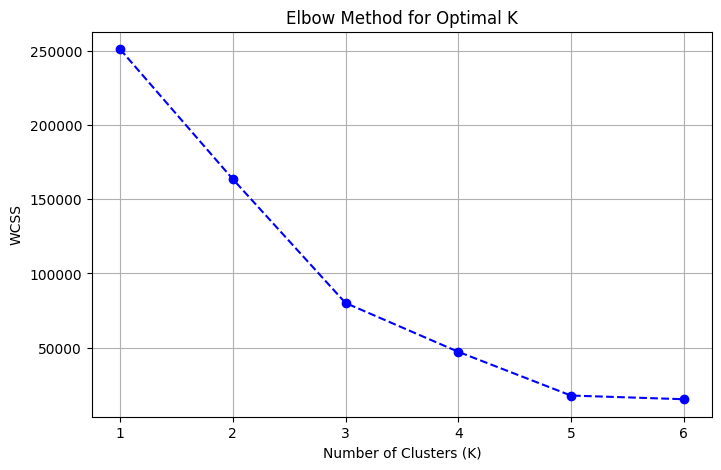

In [17]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 7),
    wcss,
    marker='o',
    color='blue',
    linestyle='--'
)

plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')

plt.xticks(range(1, 7))
plt.grid(True)

plt.show()

In [18]:
optimal_k = 5

final_model = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

df['Final_Cluster'] = final_model.fit_predict(X)

final_centroids = final_model.cluster_centers_

print("Final Model Trained Successfully!")

print("\nFinal Centroids:")
print(final_centroids)

Final Model Trained Successfully!

Final Centroids:
[[88.7027027  18.08108108]
 [88.05263158 82.18421053]
 [54.1625     49.7625    ]
 [25.13636364 79.18181818]
 [24.95652174 21.        ]]


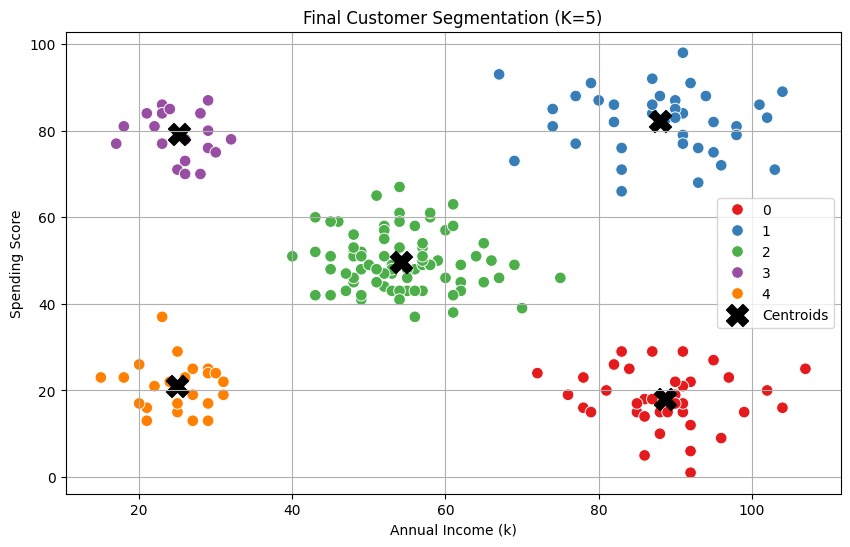

In [19]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Annual_Income_k',
    y='Spending_Score',
    hue='Final_Cluster',
    palette='Set1',
    s=70
)

plt.scatter(
    final_centroids[:, 0],
    final_centroids[:, 1],
    color='black',
    marker='X',
    s=250,
    label='Centroids'
)

plt.title('Final Customer Segmentation (K=5)')
plt.xlabel('Annual Income (k)')
plt.ylabel('Spending Score')

plt.legend()
plt.grid(True)
plt.show()

In [20]:
summary = df.groupby('Final_Cluster').agg(
    Total_Customers=('CustomerID', 'count'),
    Average_Income=('Annual_Income_k', 'mean'),
    Average_Spending=('Spending_Score', 'mean')
)

print("Customer Segmentation Summary:")

display(summary)

Customer Segmentation Summary:


,Total_Customers,Average_Income,Average_Spending
Final_Cluster,,,
0,37,88.702703,18.081081
1,38,88.052632,82.184211
2,80,54.162500,49.762500
3,22,25.136364,79.181818
4,23,24.956522,21.000000


In [21]:
df.to_csv('Customer_Segmentation_Results.csv', index=False)

from google.colab import files

files.download('Customer_Segmentation_Results.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>